In [1]:
import pandas as pd
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")

# 1. Load dataset
df = pd.read_csv('retail_sales_dataset.csv')

In [2]:
# 2. Quick cleaning (essential for this messy dataset)
df = df.dropna(subset=['city', 'region', 'sales_amount'])
df['city'] = df['city'].str.strip().str.title()
df['region'] = df['region'].str.strip().str.title()
df['order_status'] = df['order_status'].str.strip().str.title()

In [3]:
# Filter out cancelled orders and cap extreme synthetic outliers (e.g., 99th percentile)
df = df[df['order_status'] != 'Cancelled']
sales_cap = df['sales_amount'].quantile(0.99)
df = df[df['sales_amount'] <= sales_cap]

In [4]:
# Clean days_to_ship (remove negative or extreme values)
df = df[(df['days_to_ship'] >= 0) & (df['days_to_ship'] <= 30)]

In [5]:
# 3. Aggregate Demand (Sales & Orders) vs. Presence Proxy (Avg Days to Ship)
city_df = df.groupby(['region', 'city']).agg(
    total_sales=('sales_amount', 'sum'),
    total_orders=('order_id', 'count'),
    avg_ship_days=('days_to_ship', 'mean'),
    avg_shipping_cost=('shipping_cost', 'mean')
).reset_index()

In [6]:
# 4. Add coordinates for Indian cities in the dataset
city_coords = {
    'Mumbai': (19.0760, 72.8777), 'Pune': (18.5204, 73.8567),
    'Surat': (21.1702, 72.8311), 'Ahmedabad': (23.0225, 72.5714),
    'Bangalore': (12.9716, 77.5946), 'Chennai': (13.0827, 80.2707),
    'Kochi': (9.9312, 76.2673), 'Hyderabad': (17.3850, 78.4867),
    'Delhi': (28.7041, 77.1025), 'Amritsar': (31.6340, 74.8723),
    'Chandigarh': (30.7333, 76.7794), 'Ludhiana': (30.9010, 75.8573),
    'Jaipur': (26.9124, 75.7873), 'Lucknow': (26.8467, 80.9462),
    'Patna': (25.5941, 85.1376), 'Guwahati': (26.1445, 91.7362),
    'Bhubaneswar': (20.2961, 85.8245), 'Kolkata': (22.5726, 88.3639),
    'Raipur': (21.2514, 81.6296), 'Nagpur': (21.1458, 79.0882),
    'Bhopal': (23.2599, 77.4126), 'Indore': (22.7196, 75.8577)
}

city_df['lat'] = city_df['city'].map(lambda x: city_coords.get(x, (None, None))[0])
city_df['lon'] = city_df['city'].map(lambda x: city_coords.get(x, (None, None))[1])

In [7]:
# Check if any city in the CSV wasn't in the dictionary above
missing_cities = city_df[city_df['lat'].isna()]['city'].tolist()
if missing_cities:
    print("Add coordinates for these cities:", missing_cities)

city_map_df = city_df.dropna(subset=['lat', 'lon']).copy()

In [12]:
# 5. Expansion Opportunity Score: High Sales * Slow Shipping (low local presence)
city_map_df['expansion_score'] = (
    (city_map_df['total_sales'] / city_map_df['total_sales'].max()) *
    (city_map_df['avg_ship_days'] / city_map_df['avg_ship_days'].max())
)

# Display Top 5 Expansion Target Cities
city_map_df.sort_values('expansion_score', ascending=False)[
    ['city', 'region', 'total_sales', 'total_orders', 'avg_ship_days', 'expansion_score']
].head(5)

,city,region,total_sales,total_orders,avg_ship_days,expansion_score
13,Chennai,South,14531594.52,213,5.549296,0.924883
5,Guwahati,East,11696851.59,215,5.613953,0.753136
10,Delhi,North,11158447.86,184,5.798913,0.742140
14,Hyderabad,South,11171310.11,202,5.450495,0.698354
17,Mumbai,West,10308785.56,206,5.781553,0.683577


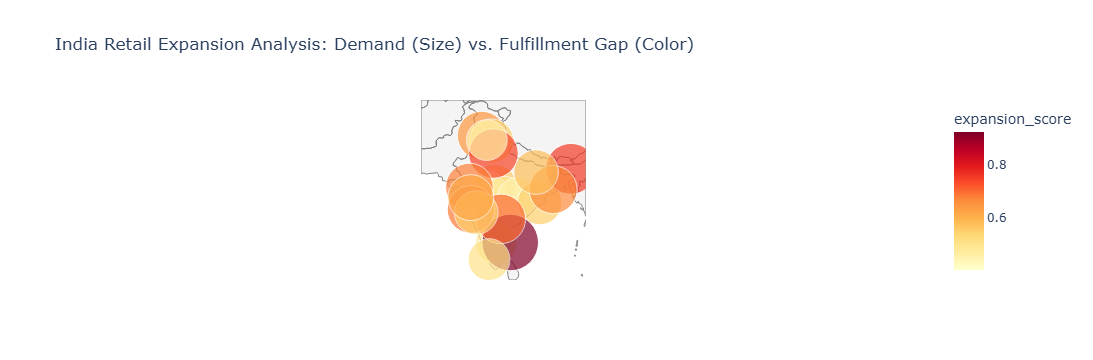

In [11]:
# 6. Plot Interactive Map
fig = px.scatter_geo(
    city_map_df,
    lat="lat",
    lon="lon",
    size="total_sales",
    color="expansion_score",
    hover_name="city",
    hover_data={"region": True, "total_sales": ":,.0f", "avg_ship_days": ":.1f", "lat": False, "lon": False},
    color_continuous_scale="YlOrRd",
    size_max=40,
    scope="asia",
    center={"lat": 22.5, "lon": 79.0},
    title="India Retail Expansion Analysis: Demand (Size) vs. Fulfillment Gap (Color)"
)
fig.update_geos(
    lataxis_range=[6, 37],
    lonaxis_range=[67, 98],
    showcountries=True,
    countrycolor="Gray",
    showland=True,
    landcolor="#F4F4F4"
)
fig.write_html("india_expansion_map.html")
fig.show()

### Key Findings & Expansion Recommendations
- **Top Priority Markets:** **Chennai** (₹14.53M sales, 5.55 avg ship days) and **Guwahati** (₹11.70M sales, 5.61 avg ship days) combine the highest revenue demand with significant shipping delays.
- **Secondary Targets:** **Delhi**, **Hyderabad**, and **Mumbai** also exhibit strong order volume paired with 5.4–5.8 day fulfillment times, indicating underserved local warehouse/store presence.